In [2]:
import pandas as pd

df = pd.read_csv('https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv')
df.head(100)



,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,0,3,male,NaN,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
96,0,1,male,71.0,0,0,34.6542,C,First,man,True,A,Cherbourg,no,True
97,1,1,male,23.0,0,1,63.3583,C,First,man,True,D,Cherbourg,yes,False
98,1,2,female,34.0,0,1,23.0000,S,Second,woman,False,NaN,Southampton,yes,False


In [3]:
df.describe(include='all')

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
count,891.000000,891.000000,891,714.000000,891.000000,891.000000,891.000000,889,891,891,891,203,889,891,891
unique,NaN,NaN,2,NaN,NaN,NaN,NaN,3,3,3,2,7,3,2,2
top,NaN,NaN,male,NaN,NaN,NaN,NaN,S,Third,man,True,C,Southampton,no,True
freq,NaN,NaN,577,NaN,NaN,NaN,NaN,644,491,537,537,59,644,549,537
mean,0.383838,2.308642,NaN,29.699118,0.523008,0.381594,32.204208,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,0.486592,0.836071,NaN,14.526497,1.102743,0.806057,49.693429,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,0.000000,1.000000,NaN,0.420000,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,0.000000,2.000000,NaN,20.125000,0.000000,0.000000,7.910400,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,0.000000,3.000000,NaN,28.000000,0.000000,0.000000,14.454200,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,1.000000,3.000000,NaN,38.000000,1.000000,0.000000,31.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


/var/folders/h4/xrdpcvx95xlcmv9ln79pv4xc0000gn/T/ipykernel_29450/1378741358.py:3: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([df.loc[df['survived'] == 1, 'age'].dropna(), df.loc[df['survived'] == 0, 'age'].dropna()],


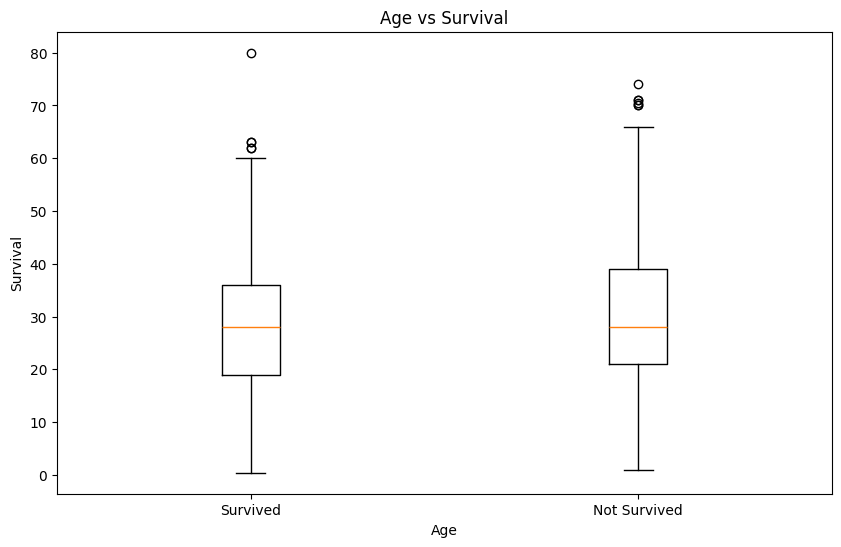

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 6))
plt.boxplot([df.loc[df['survived'] == 1, 'age'].dropna(), df.loc[df['survived'] == 0, 'age'].dropna()],
    labels=['Survived', 'Not Survived'])
plt.xlabel('Age')
plt.ylabel('Survival')
plt.title('Age vs Survival')
plt.show()


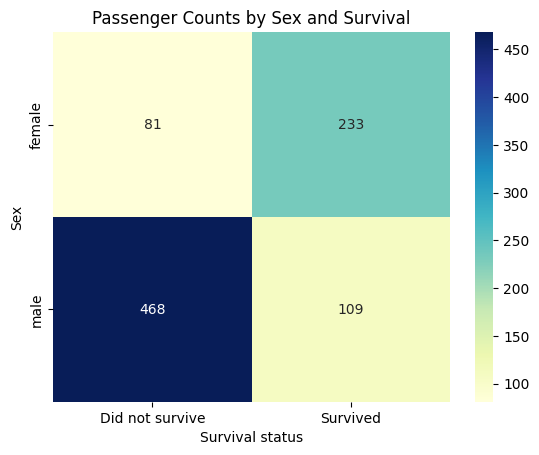

In [17]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

survival_counts = pd.crosstab(
    df['sex'],
    df['survived']
).rename(columns={0: 'Did not survive', 1: 'Survived'})

sns.heatmap(survival_counts, annot=True, fmt='d', cmap='YlGnBu')
plt.xlabel('Survival status')
plt.ylabel('Sex')
plt.title('Passenger Counts by Sex and Survival')
plt.show()

/Users/judy/Library/Python/3.9/lib/python/site-packages/numpy/lib/_function_base_impl.py:2922: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/Users/judy/Library/Python/3.9/lib/python/site-packages/numpy/lib/_function_base_impl.py:2923: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


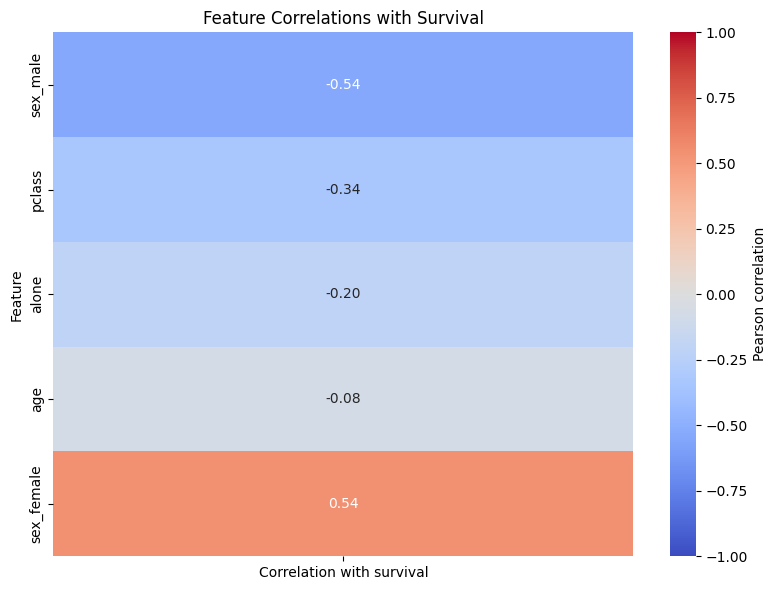

In [19]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Encode categorical features; exclude the target and its duplicate label.
features = pd.get_dummies(
    #df.drop(columns=['survived', 'alive'], errors='ignore'),
    df[['pclass', 'sex','age', 'alone',]], 
    dummy_na=True,
    dtype=float
)

correlations = features.corrwith(df['survived']).dropna().sort_values()
correlation_map = correlations.to_frame(name='Correlation with survival')

plt.figure(figsize=(8, max(6, len(correlations) * 0.35)))
sns.heatmap(
    correlation_map,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    vmin=-1,
    vmax=1,
    cbar_kws={'label': 'Pearson correlation'}
)
plt.title('Feature Correlations with Survival')
plt.ylabel('Feature')
plt.xlabel('')
plt.tight_layout()
plt.show()

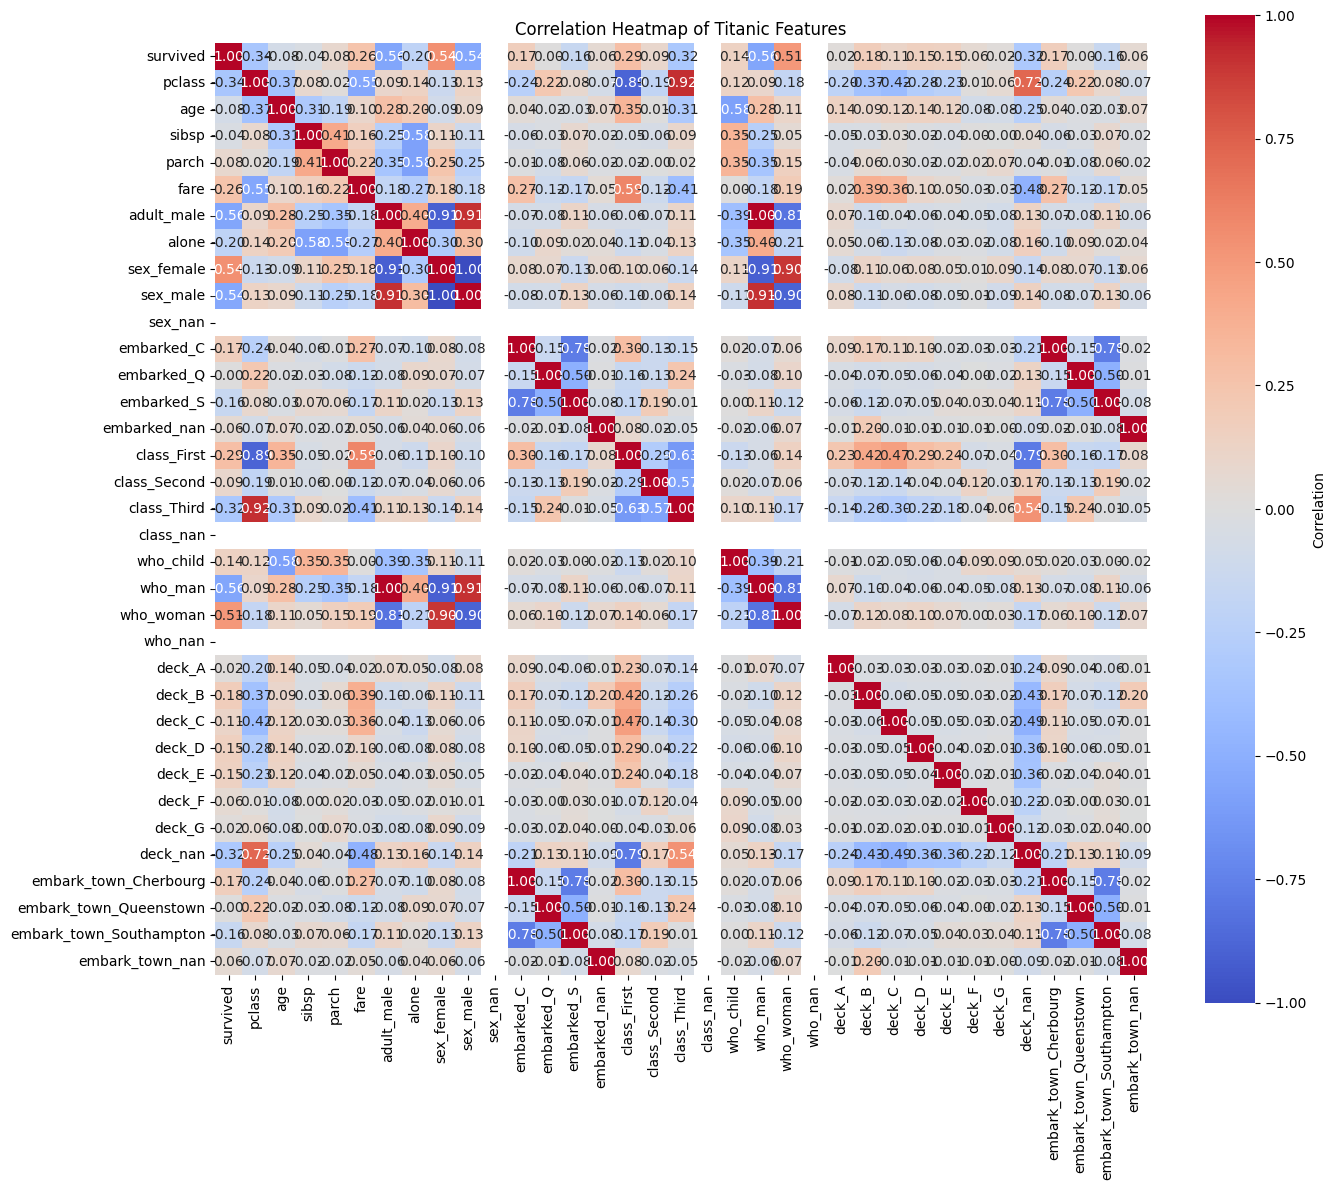

In [20]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Convert categorical columns to numeric indicators for correlation.
# 'alive' duplicates 'survived', so omit it.
features = pd.get_dummies(
    df.drop(columns=['alive'], errors='ignore'),
    dummy_na=True,
    dtype=float
)

correlation_matrix = features.corr()

plt.figure(figsize=(14, 12))
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    cbar_kws={'label': 'Correlation'}
)
plt.title('Correlation Heatmap of Titanic Features')
plt.tight_layout()
plt.show()

In [21]:
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder

X = df.drop(columns=['survived', 'alive'], errors='ignore')
y = df['survived']

numeric_features = X.select_dtypes(include='number').columns
categorical_features = X.select_dtypes(exclude='number').columns

preprocessor = ColumnTransformer([
    ('numeric', SimpleImputer(strategy='median'), numeric_features),
    ('categorical', make_pipeline(
        SimpleImputer(strategy='most_frequent'),
        OneHotEncoder(handle_unknown='ignore')
    ), categorical_features)
])

model = make_pipeline(preprocessor, LinearRegression())
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model.fit(X_train, y_train)
predictions = model.predict(X_test)

print('R²:', round(r2_score(y_test, predictions), 3))
print('RMSE:', round(mean_squared_error(y_test, predictions) ** 0.5, 3))
print(pd.DataFrame({
    'Actual survival': y_test,
    'Predicted score': predictions
}).head())

R²: 0.42
RMSE: 0.375
     Actual survival  Predicted score
709                1         0.096313
439                0         0.223572
840                0         0.083874
720                1         0.818661
39                 1         0.696526


/Users/judy/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/judy/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/judy/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_


In [22]:
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

# Keep only the target and the two requested features.
data = df[['survived', 'pclass', 'sex']].dropna()
X = pd.get_dummies(
    data[['pclass', 'sex']],
    columns=['sex'],
    drop_first=True,
    dtype=int
)
y = data['survived']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)
predictions = model.predict(X_test)

print('R²:', round(r2_score(y_test, predictions), 3))
print('RMSE:', round(mean_squared_error(y_test, predictions) ** 0.5, 3))
print(pd.DataFrame({
    'Actual survival': y_test,
    'Predicted score': predictions
}).head())

R²: 0.401
RMSE: 0.381
     Actual survival  Predicted score
709                1         0.096916
439                0         0.247602
840                0         0.096916
720                1         0.766453
39                 1         0.615767
